In [1]:
import pandas as pd
import numpy as np
import os
import joblib

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

In [2]:
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "stroke"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models",
    "stroke"
)

print("Paths configured successfully!")

Paths configured successfully!


In [3]:
X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_train.csv")
)

X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_test.csv")
)

y_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_train.csv")
).squeeze()

y_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_test.csv")
).squeeze()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4088, 21)
Testing data: (1022, 21)


In [4]:
models = {
    "Logistic Regression": joblib.load(
        os.path.join(MODEL_DIR, "logistic_regression.pkl")
    ),

    "Decision Tree": joblib.load(
        os.path.join(MODEL_DIR, "decision_tree.pkl")
    ),

    "Random Forest": joblib.load(
        os.path.join(MODEL_DIR, "random_forest.pkl")
    ),

    "SVM": joblib.load(
        os.path.join(MODEL_DIR, "svm.pkl")
    ),

    "XGBoost": joblib.load(
        os.path.join(MODEL_DIR, "xgboost.pkl")
    )
}

print("All five models loaded successfully!")

All five models loaded successfully!


In [5]:
predictions = {}
probabilities = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions and probabilities generated successfully!")

Predictions and probabilities generated successfully!


In [6]:
for name in models:

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    print(f"\n{name}")
    print(cm)


Logistic Regression
[[723 249]
 [ 10  40]]

Decision Tree
[[945  27]
 [ 45   5]]

Random Forest
[[950  22]
 [ 44   6]]

SVM
[[759 213]
 [ 20  30]]

XGBoost
[[824 148]
 [ 16  34]]


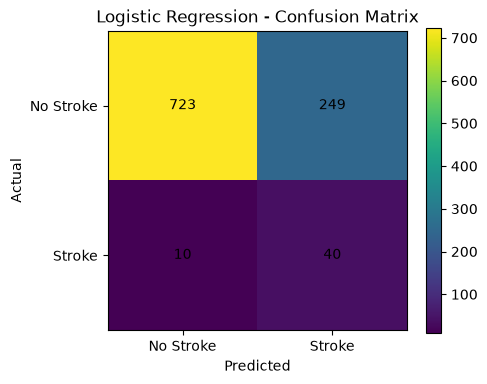

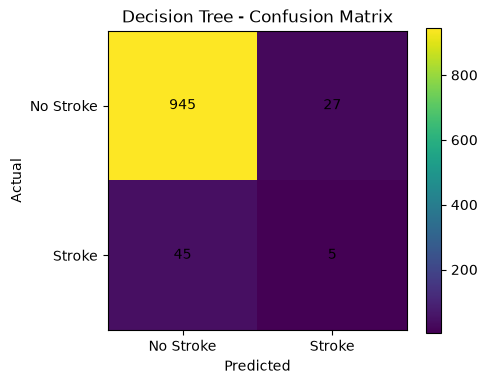

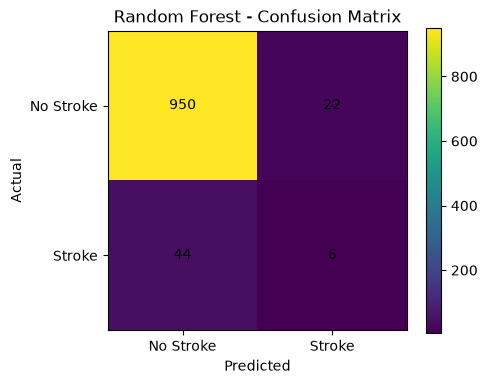

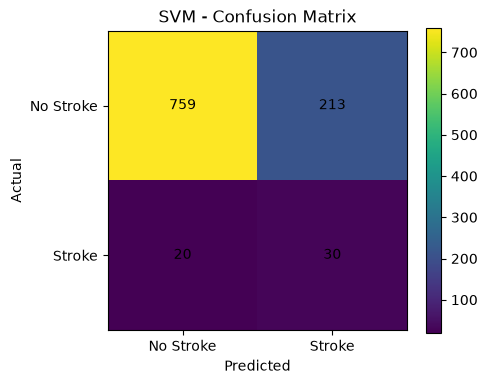

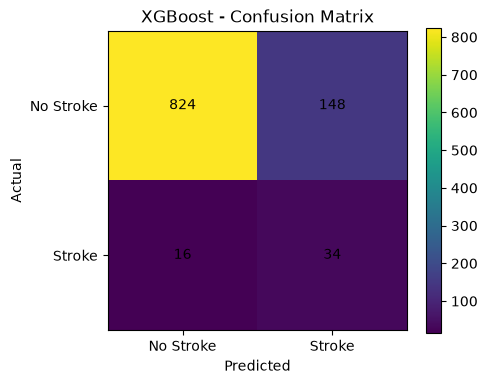

In [7]:
for name in models:

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    plt.figure(figsize=(5, 4))

    plt.imshow(cm)

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks([0, 1], ["No Stroke", "Stroke"])
    plt.yticks([0, 1], ["No Stroke", "Stroke"])

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [8]:
for name in models:

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["No Stroke", "Stroke"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

Decision Tree
              precision    recall  f1-score   support

   No Stroke       0.95      0.97      0.96       972
      Stroke       0.16      0.10      0.12        50

    accuracy                           0.93      1022
   macro avg       0.56      0.54      0.54      1022
weighted avg       0.92      0.93      0.92      1022

Random Forest
              precision    recall  f1-score   support

   No Stroke       0.96      0.98      0.97       972
      Stroke       0.21      0.12      0.15        50

    accuracy                           0.94      1022
   macro avg       0.59      0.55      0.56      1022
weighted avg       0.92   

In [9]:
evaluation_results = []

for name in models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )
    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )
    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.746575,0.138408,0.80,0.235988,0.843827,0.268185
1,Decision Tree,0.929550,0.156250,0.10,0.121951,0.536111,0.059656
2,Random Forest,0.935421,0.214286,0.12,0.153846,0.775453,0.132991
3,SVM,0.772016,0.123457,0.60,0.204778,0.789239,0.172088
4,XGBoost,0.839530,0.186813,0.68,0.293103,0.842490,0.228639


In [10]:
evaluation_display = evaluation_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

evaluation_display[metric_columns] = (
    evaluation_display[metric_columns] * 100
).round(2)

evaluation_display

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,74.66,13.84,80.0,23.60,84.38,26.82
1,Decision Tree,92.95,15.62,10.0,12.20,53.61,5.97
2,Random Forest,93.54,21.43,12.0,15.38,77.55,13.30
3,SVM,77.20,12.35,60.0,20.48,78.92,17.21
4,XGBoost,83.95,18.68,68.0,29.31,84.25,22.86


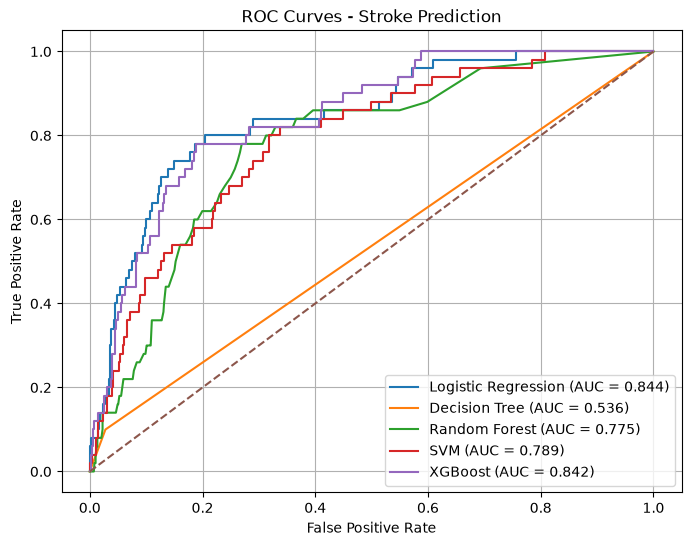

In [11]:
plt.figure(figsize=(8, 6))

for name in models:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Stroke Prediction")

plt.legend()
plt.grid(True)
plt.show()

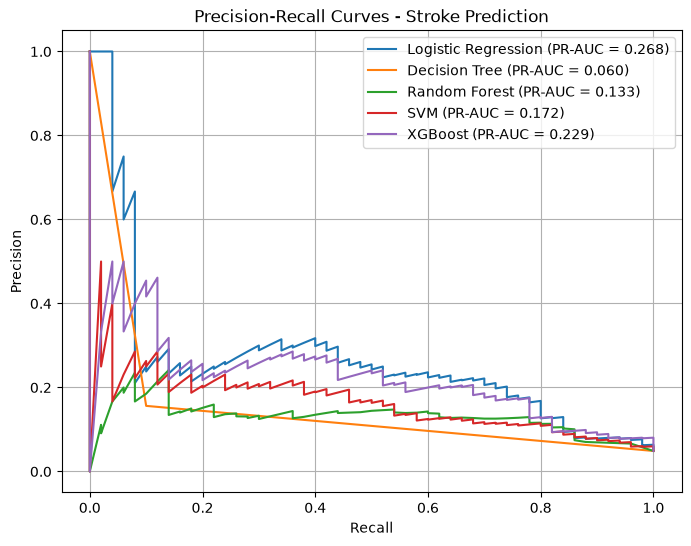

In [12]:
plt.figure(figsize=(8, 6))

for name in models:

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities[name]
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Stroke Prediction")

plt.legend()
plt.grid(True)
plt.show()

In [13]:
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = {}

for name in models:

    model_results = []

    y_prob = probabilities[name]

    for threshold in thresholds:

        y_pred_threshold = (
            y_prob >= threshold
        ).astype(int)

        precision = precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        model_results.append({
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

    threshold_results[name] = pd.DataFrame(
        model_results
    )

print("Threshold analysis completed!")

Threshold analysis completed!


In [14]:
threshold_results["Logistic Regression"]
threshold_results["XGBoost"]

,Threshold,Precision,Recall,F1 Score
0,0.10,0.095238,0.88,0.171875
1,0.15,0.097156,0.82,0.173729
2,0.20,0.105670,0.82,0.187215
3,0.25,0.114846,0.82,0.201474
4,0.30,0.129747,0.82,0.224044
5,0.35,0.134021,0.78,0.228739
6,0.40,0.152344,0.78,0.254902
7,0.45,0.171296,0.74,0.278195
8,0.50,0.186813,0.68,0.293103
9,0.55,0.202532,0.64,0.307692


In [15]:
for name, result in threshold_results.items():

    best_row = result.loc[
        result["F1 Score"].idxmax()
    ]

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        f"Best threshold: "
        f"{best_row['Threshold']:.2f}"
    )

    print(
        f"Precision: "
        f"{best_row['Precision'] * 100:.2f}%"
    )

    print(
        f"Recall: "
        f"{best_row['Recall'] * 100:.2f}%"
    )

    print(
        f"F1 Score: "
        f"{best_row['F1 Score'] * 100:.2f}%"
    )

Logistic Regression
Best threshold: 0.85
Precision: 30.65%
Recall: 38.00%
F1 Score: 33.93%
Decision Tree
Best threshold: 0.10
Precision: 15.62%
Recall: 10.00%
F1 Score: 12.20%
Random Forest
Best threshold: 0.20
Precision: 14.45%
Recall: 50.00%
F1 Score: 22.42%
SVM
Best threshold: 0.10
Precision: 16.89%
Recall: 50.00%
F1 Score: 25.25%
XGBoost
Best threshold: 0.70
Precision: 27.94%
Recall: 38.00%
F1 Score: 32.20%


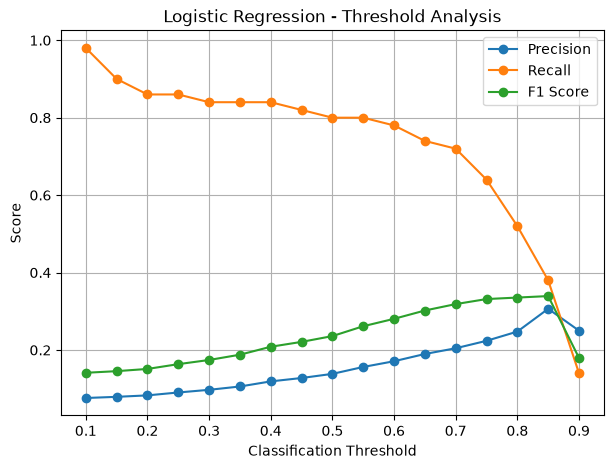

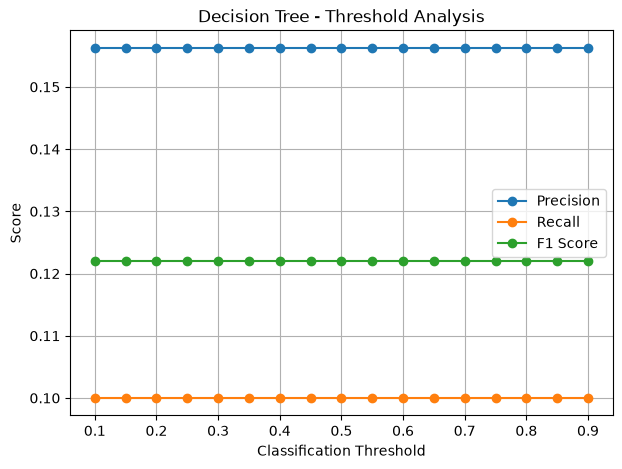

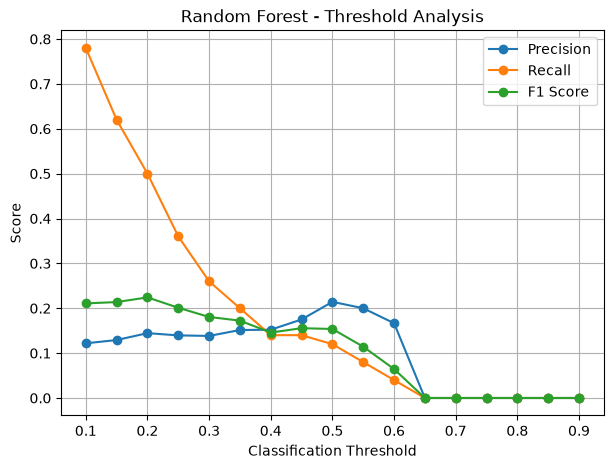

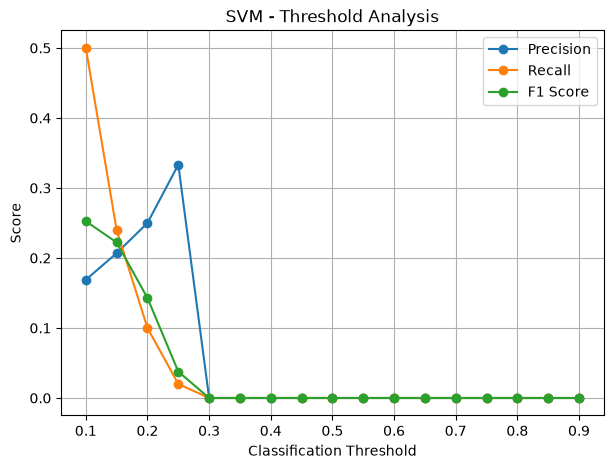

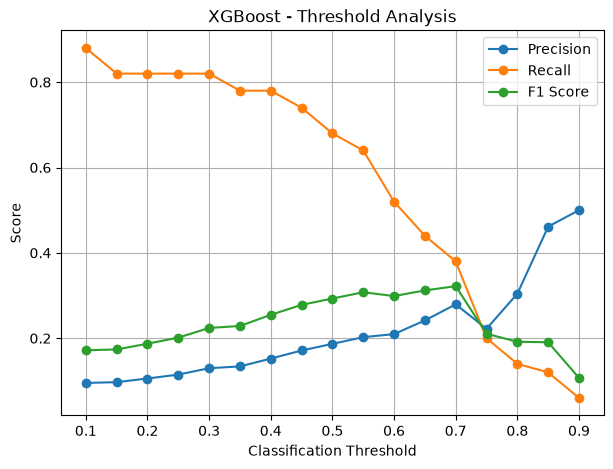

In [16]:
for name, result in threshold_results.items():

    plt.figure(figsize=(7, 5))

    plt.plot(
        result["Threshold"],
        result["Precision"],
        marker="o",
        label="Precision"
    )

    plt.plot(
        result["Threshold"],
        result["Recall"],
        marker="o",
        label="Recall"
    )

    plt.plot(
        result["Threshold"],
        result["F1 Score"],
        marker="o",
        label="F1 Score"
    )

    plt.xlabel("Classification Threshold")
    plt.ylabel("Score")

    plt.title(
        f"{name} - Threshold Analysis"
    )

    plt.legend()
    plt.grid(True)
    plt.show()

In [17]:
evaluation_path = os.path.join(
    PROCESSED_DIR,
    "model_evaluation.csv"
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("Evaluation results saved successfully!")
print(evaluation_path)

Evaluation results saved successfully!
d:\Explainable-AI-CDSS\datasets\processed\stroke\model_evaluation.csv


In [18]:
for name, result in threshold_results.items():

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "")
    )

    path = os.path.join(
        PROCESSED_DIR,
        f"{safe_name}_threshold_analysis.csv"
    )

    result.to_csv(
        path,
        index=False
    )

print("Threshold analysis files saved!")

Threshold analysis files saved!


In [19]:
print("=" * 90)
print("STROKE MODEL EVALUATION")
print("=" * 90)

final_display = evaluation_df.copy()

final_display[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ]
] *= 100

final_display[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ]
] = final_display[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].round(2)

final_display

STROKE MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,74.66,13.84,80.0,23.60,84.38,26.82
1,Decision Tree,92.95,15.62,10.0,12.20,53.61,5.97
2,Random Forest,93.54,21.43,12.0,15.38,77.55,13.30
3,SVM,77.20,12.35,60.0,20.48,78.92,17.21
4,XGBoost,83.95,18.68,68.0,29.31,84.25,22.86


In [20]:
# ============================================================
# CELL 20 — Display Complete Threshold Tables
# ============================================================

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("=" * 80)
print("LOGISTIC REGRESSION — THRESHOLD ANALYSIS")
print("=" * 80)

display(threshold_results["Logistic Regression"])

print("\n")
print("=" * 80)
print("XGBOOST — THRESHOLD ANALYSIS")
print("=" * 80)

display(threshold_results["XGBoost"])

LOGISTIC REGRESSION — THRESHOLD ANALYSIS


,Threshold,Precision,Recall,F1 Score
0,0.10,0.076087,0.98,0.141210
1,0.15,0.079086,0.90,0.145396
2,0.20,0.082852,0.86,0.151142
3,0.25,0.090336,0.86,0.163498
4,0.30,0.097222,0.84,0.174274
5,0.35,0.105793,0.84,0.187919
6,0.40,0.118980,0.84,0.208437
7,0.45,0.127726,0.82,0.221024
8,0.50,0.138408,0.80,0.235988
9,0.55,0.156250,0.80,0.261438




XGBOOST — THRESHOLD ANALYSIS


,Threshold,Precision,Recall,F1 Score
0,0.10,0.095238,0.88,0.171875
1,0.15,0.097156,0.82,0.173729
2,0.20,0.105670,0.82,0.187215
3,0.25,0.114846,0.82,0.201474
4,0.30,0.129747,0.82,0.224044
5,0.35,0.134021,0.78,0.228739
6,0.40,0.152344,0.78,0.254902
7,0.45,0.171296,0.74,0.278195
8,0.50,0.186813,0.68,0.293103
9,0.55,0.202532,0.64,0.307692


In [26]:
# ============================================================
# LOGISTIC REGRESSION THRESHOLD TABLE
# ============================================================

lr_thresholds = threshold_results["Logistic Regression"].copy()

print("Logistic Regression Threshold Analysis")
print("=" * 70)

display(lr_thresholds)

Logistic Regression Threshold Analysis


,Threshold,Precision,Recall,F1 Score
0,0.10,0.076087,0.98,0.141210
1,0.15,0.079086,0.90,0.145396
2,0.20,0.082852,0.86,0.151142
3,0.25,0.090336,0.86,0.163498
4,0.30,0.097222,0.84,0.174274
5,0.35,0.105793,0.84,0.187919
6,0.40,0.118980,0.84,0.208437
7,0.45,0.127726,0.82,0.221024
8,0.50,0.138408,0.80,0.235988
9,0.55,0.156250,0.80,0.261438


In [27]:
# ============================================================
# XGBOOST THRESHOLD TABLE
# ============================================================

xgb_thresholds = threshold_results["XGBoost"].copy()

print("XGBoost Threshold Analysis")
print("=" * 70)

display(xgb_thresholds)

XGBoost Threshold Analysis


,Threshold,Precision,Recall,F1 Score
0,0.10,0.095238,0.88,0.171875
1,0.15,0.097156,0.82,0.173729
2,0.20,0.105670,0.82,0.187215
3,0.25,0.114846,0.82,0.201474
4,0.30,0.129747,0.82,0.224044
5,0.35,0.134021,0.78,0.228739
6,0.40,0.152344,0.78,0.254902
7,0.45,0.171296,0.74,0.278195
8,0.50,0.186813,0.68,0.293103
9,0.55,0.202532,0.64,0.307692


In [23]:
# ============================================================
# BEST THRESHOLD FOR EVERY MODEL
# ============================================================

best_thresholds = []

for model_name, df in threshold_results.items():

    # Find F1 column automatically
    f1_column = None

    for col in df.columns:
        if "f1" in str(col).lower():
            f1_column = col
            break

    if f1_column is None:
        print(f"F1 column not found for {model_name}")
        print("Available columns:", df.columns.tolist())
        continue

    best_row = df.loc[df[f1_column].idxmax()]

    # Find other columns automatically
    threshold_col = next(
        col for col in df.columns
        if "threshold" in str(col).lower()
    )

    precision_col = next(
        col for col in df.columns
        if "precision" in str(col).lower()
    )

    recall_col = next(
        col for col in df.columns
        if "recall" in str(col).lower()
    )

    best_thresholds.append({
        "Model": model_name,
        "Best Threshold": best_row[threshold_col],
        "Precision": best_row[precision_col],
        "Recall": best_row[recall_col],
        "F1 Score": best_row[f1_column]
    })

best_threshold_df = pd.DataFrame(best_thresholds)

display(best_threshold_df)

,Model,Best Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.85,0.306452,0.38,0.339286
1,Decision Tree,0.10,0.156250,0.10,0.121951
2,Random Forest,0.20,0.144509,0.50,0.224215
3,SVM,0.10,0.168919,0.50,0.252525
4,XGBoost,0.70,0.279412,0.38,0.322034


In [25]:
# ============================================================
# SAVE BEST THRESHOLD COMPARISON
# ============================================================

import os

output_path = os.path.join(
    PROCESSED_DIR,
    "stroke_best_thresholds.csv"
)

best_threshold_df.to_csv(
    output_path,
    index=False
)

print("Best threshold comparison saved successfully.")
print("Saved to:", output_path)

Best threshold comparison saved successfully.
Saved to: d:\Explainable-AI-CDSS\datasets\processed\stroke\stroke_best_thresholds.csv


In [28]:
# ============================================================
# CELL 23 — Save Final Stroke Model
# ============================================================

import joblib
import os

# Final selected model
stroke_best_model = models["Logistic Regression"]

# Save model
best_model_path = os.path.join(
    MODEL_DIR,
    "best_model.pkl"
)

joblib.dump(
    stroke_best_model,
    best_model_path
)

print("Stroke best model saved successfully.")
print("Selected model: Logistic Regression")
print("Best F1 threshold: 0.85")
print("Model path:", best_model_path)

Stroke best model saved successfully.
Selected model: Logistic Regression
Best F1 threshold: 0.85
Model path: d:\Explainable-AI-CDSS\models\stroke\best_model.pkl


In [29]:
# ============================================================
# CELL 24 — Save Stroke Decision Threshold
# ============================================================

stroke_threshold = 0.85

threshold_path = os.path.join(
    MODEL_DIR,
    "threshold.pkl"
)

joblib.dump(
    stroke_threshold,
    threshold_path
)

print("Stroke threshold saved successfully.")
print("Threshold:", stroke_threshold)
print("Saved to:", threshold_path)

Stroke threshold saved successfully.
Threshold: 0.85
Saved to: d:\Explainable-AI-CDSS\models\stroke\threshold.pkl
